**Psychoinformatyka**

# W02. Analiza danych z zadania Stroopa

**Wersja źródła:** 1.0.7 · **Data:** 2026-11-03

Notebook obejmuje syntetyczne dane 24 uczestników: po 20 prób w warunkach zgodnym i niezgodnym. Analiza wykorzystuje medianę poprawnych czasów reakcji w obrębie każdej osoby. Efekt opisujemy w milisekundach jako warunek niezgodny minus zgodny.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261101)
rekordy = []


In [7]:
for osoba in range(1, 25):
    przesuniecie = rng.normal(0, 30)
    for warunek, dodatek, szansa in [("zgodny", 0, 0.97), ("niezgodny", 85, 0.91)]:
        for proba in range(1, 21):
            odpowiedz = rng.random() < szansa
            pominiecie = rng.random() < 0.02
            rt = (np.nan if pominiecie else float(
                rng.lognormal(np.log(520 + dodatek + przesuniecie), 0.18)))
            rekordy.append(dict(participant=f"P{osoba:02d}", trial=proba,
                condition=warunek, rt_ms=rt,
                correct=int(odpowiedz and not pominiecie)))

dane = pd.DataFrame(rekordy)


## Kontrola danych

Sprawdź jednostki i typy danych. Brak odpowiedzi pozostaje wartością brakującą RT, nie jest zastępowany zerem. Zakres od 150 do 2000 ms stosujemy jako wcześniej określoną regułę analizy.

In [8]:
assert len(dane) == 960
assert dane.groupby(["participant", "condition"]).size().eq(20).all()
print("Obserwacje:", len(dane), "| uczestnicy:", dane.participant.nunique())
print(dane.head())
wymagane = {"participant", "trial", "condition", "rt_ms", "correct"}
assert wymagane.issubset(dane.columns)
assert dane["correct"].isin([0, 1]).all()
assert dane["condition"].isin(["zgodny", "niezgodny"]).all()
print("Braki RT:", dane.rt_ms.isna().sum())
print("Poprawność [%] według warunku:")
print((100 * dane.groupby("condition").correct.mean()).round(1))

analiza = dane.loc[
    dane.correct.eq(1) & dane.rt_ms.between(150, 2000)
].copy()
print("Obserwacje w analizie RT:", len(analiza))


Obserwacje: 960 | uczestnicy: 24
  participant  trial condition       rt_ms  correct
0         P01      1    zgodny  525.949660        1
1         P01      2    zgodny         NaN        0
2         P01      3    zgodny  418.870857        1
3         P01      4    zgodny  554.629737        1
4         P01      5    zgodny  513.266673        1
Braki RT: 19
Poprawność [%] według warunku:
condition
niezgodny    88.5
zgodny       94.6
Name: correct, dtype: float64
Obserwacje w analizie RT: 879


## Interferencja wewnątrzosobnicza

Dla każdej osoby policz medianę RT w obu warunkach. Nie traktuj 960 prób jako 960 niezależnych osób. Zwróć uwagę, że kierunek różnicy jest zdefiniowany przez kolejność odejmowania.

In [9]:
mediany = analiza.groupby(["participant", "condition"]).rt_ms.median().unstack()
assert mediany[["zgodny", "niezgodny"]].notna().all().all()
mediany["interferencja_ms"] = mediany["niezgodny"] - mediany["zgodny"]
print(mediany.round(1).head())
print("Mediana różnic uczestników [ms]:",
      round(mediany["interferencja_ms"].median(), 1))


condition    niezgodny  zgodny  interferencja_ms
participant                                     
P01              526.5   488.3              38.2
P02              667.6   524.9             142.8
P03              635.9   537.7              98.2
P04              527.2   482.5              44.7
P05              577.5   531.1              46.5
Mediana różnic uczestników [ms]: 94.1


## Wykresy

Pierwszy wykres pokazuje rozkład RT, drugi parowane mediany indywidualne. Oba zawierają osie z jednostkami. Wybrana wielkość efektu została narzucona podczas generowania danych.

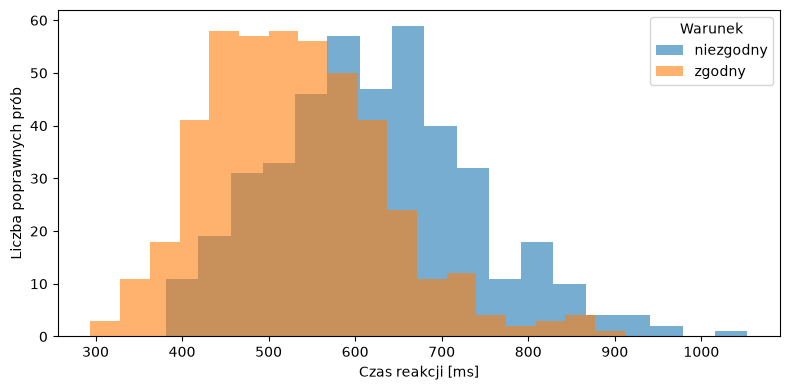

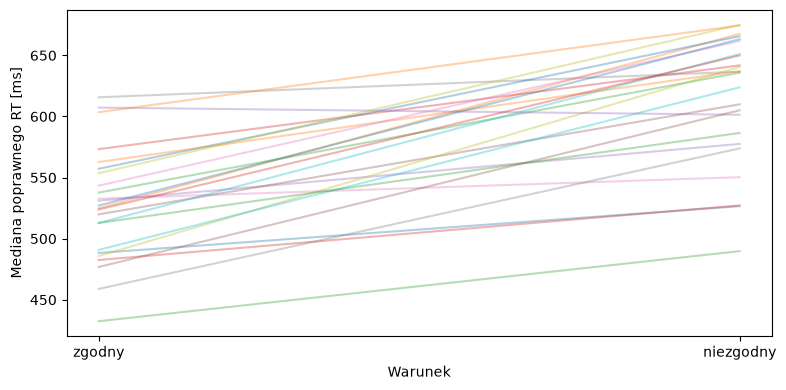

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for nazwa, w in analiza.groupby("condition"):
    ax.hist(w.rt_ms, bins=18, alpha=0.6, label=nazwa)
ax.set_xlabel("Czas reakcji [ms]")
ax.set_ylabel("Liczba poprawnych prób")
ax.legend(title="Warunek")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for _, w in mediany.iterrows():
    ax.plot(["zgodny", "niezgodny"],
            [w["zgodny"], w["niezgodny"]], alpha=0.35)
ax.set_xlabel("Warunek")
ax.set_ylabel("Mediana poprawnego RT [ms]")
fig.tight_layout()
plt.show()


## Odtwarzalność i wnioski

Wypisz liczbę uczestników, liczbę prób odrzuconych z analizy RT i medianę różnic wewnątrzosobniczych. Zachowaj ziarno generatora oraz reguły filtrowania